# Music Tribes Explorer

Unsupervised clustering (K-Means) + dimensionality reduction (PCA / UMAP) on the
Spotify 1921–2020 corpus.

Runs end-to-end from a clean kernel. Inputs are the preprocessing notebook's frozen artifacts
(`tracks_100k.parquet`, `scaler.joblib`) — nothing is re-preprocessed and the scaler is
never re-fit.

**Feature set.** The model uses the **10 continuous audio features**. The shared scaler
standardizes all 12, but `mode` (binary) and `time_signature` (a near-constant category) are
left out of the distance: §8 shows that including them splits one sonic tribe into a major-key
and a minor-key copy and divides the UMAP map along key signature. The DJ Engine's k-NN graph
is built on the same 10 features, so the map and the graph share one space.

**Outputs written to `OUT_DIR`:** `kmeans.joblib`, `tracks_clustered.parquet`,
`cluster_metadata.json`, `map_data.json`, cluster/decade CSV tables, and the report figures.

Requires: `pip install pandas pyarrow scikit-learn umap-learn matplotlib joblib`

In [1]:
import os, json, time, warnings
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, joblib
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import (silhouette_score, silhouette_samples, davies_bouldin_score,
                             calinski_harabasz_score, normalized_mutual_info_score,
                             adjusted_rand_score)
from sklearn.manifold import trustworthiness

SEED = 42                                   # shared project seed
DATA_DIR = "data"                           # written by preprocessing.ipynb
OUT_DIR  = "outputs/music_tribes"
FIG_DIR  = f"{OUT_DIR}/figures"
os.makedirs(OUT_DIR, exist_ok=True)
os.makedirs(FIG_DIR, exist_ok=True)

AUDIO_FEATURES = ['danceability','energy','loudness','speechiness','acousticness',
                  'instrumentalness','liveness','valence','tempo','duration_ms',
                  'mode','time_signature']          # fixed order - the scaler expects it
FEATURES = [f for f in AUDIO_FEATURES if f not in ('mode','time_signature')]   # the 10 the model uses
RADAR_FEATURES = [f for f in FEATURES if f != 'duration_ms']   # radar charts + website profiles
K_FINAL = 6
# one colour per tribe (cluster id order); tribes kept from the earlier 12-feature run keep their colour
PALETTE = ["#2E4057","#4C9F70","#7B2D8E","#17BEBB","#F3A712","#E4572E"]

plt.rcParams.update({"font.size": 9, "axes.grid": True, "grid.alpha": .25,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "figure.dpi": 150, "savefig.bbox": "tight"})

def save_fig(fig, filename):
    """Write a report figure to FIG_DIR and show it inline."""
    fig.savefig(f"{FIG_DIR}/{filename}")
    plt.show()

## 1. Load the shared artifacts

`scaler.joblib` is loaded, never fitted. It standardizes all 12 features; the model keeps the
10 continuous columns (`X`). The full 12-D matrix (`X12`) is kept only for the comparison in §8.

In [2]:
tracks = pd.read_parquet(f"{DATA_DIR}/tracks_100k.parquet")
scaler = joblib.load(f"{DATA_DIR}/scaler.joblib")

X12 = scaler.transform(tracks[AUDIO_FEATURES].values)     # all 12 standardized features
FEAT_IDX = [AUDIO_FEATURES.index(f) for f in FEATURES]
X   = X12[:, FEAT_IDX]                                     # the 10 the model uses

print(tracks.shape, X.shape, X12.shape)
print("decade distribution preserved:", tracks.decade.value_counts().sort_index().to_dict())

(100001, 28) (100001, 10) (100001, 12)
decade distribution preserved: {1920: 1253, 1930: 2223, 1940: 2840, 1950: 5993, 1960: 8144, 1970: 10629, 1980: 14119, 1990: 18613, 2000: 14664, 2010: 18215, 2020: 3308}


## 2. Choosing k — elbow, silhouette, Davies–Bouldin

K-Means for k = 2…15 with `n_init=10`. Silhouette is O(n²), so it is computed on a fixed
10,000-track subsample. The same sweep is run on all 12 features for the comparison in §8.

In [3]:
def sweep(M, ks=range(2, 16)):
    rows = []
    for k in ks:
        km  = KMeans(n_clusters=k, random_state=SEED, n_init=10)
        lab = km.fit_predict(M)
        rows.append(dict(k=k, inertia=km.inertia_,
                         silhouette=silhouette_score(M, lab, sample_size=10000, random_state=SEED),
                         davies_bouldin=davies_bouldin_score(M, lab),
                         calinski_harabasz=calinski_harabasz_score(M, lab),
                         smallest_cluster=int(np.bincount(lab).min())))
    return pd.DataFrame(rows)

sw10 = sweep(X);   sw10.to_csv(f"{OUT_DIR}/k_sweep_10feature.csv", index=False)
sw12 = sweep(X12); sw12.to_csv(f"{OUT_DIR}/k_sweep_12feature.csv", index=False)
sw10.round(4)

,k,inertia,silhouette,davies_bouldin,calinski_harabasz,smallest_cluster
0,2,797776.5741,0.2228,1.8365,24676.9511,38417
1,3,700476.1632,0.2460,1.4842,20997.3457,5104
2,4,635582.6638,0.2170,1.5272,18830.5781,5049
3,5,580921.6185,0.1868,1.6840,17803.9597,4981
4,6,540422.3874,0.1867,1.6137,16809.1338,4820
5,7,509132.7803,0.1887,1.4805,15892.6131,308
6,8,481770.2504,0.1644,1.5215,15207.0226,306
7,9,455941.1897,0.1704,1.4647,14767.8520,283
8,10,433421.6719,0.1682,1.4223,14386.1366,294
9,11,418648.9607,0.1627,1.4344,13757.0975,294


In [4]:
def knee(df):
    """Elbow point = the k whose inertia is furthest from the chord joining the endpoints."""
    k = df.k.values.astype(float); I = df.inertia.values
    x = (k-k.min())/(k.max()-k.min()); y = (I-I.min())/(I.max()-I.min())
    d = np.abs((x[-1]-x[0])*(y[0]-y)-(x[0]-x)*(y[-1]-y[0]))/np.hypot(x[-1]-x[0], y[-1]-y[0])
    return int(k[d.argmax()])

print("knee (10 features):", knee(sw10), "| knee (12 features):", knee(sw12))
print("silhouette argmax  :", int(sw10.loc[sw10.silhouette.idxmax(), 'k']))

knee (10 features): 6 | knee (12 features): 6
silhouette argmax  : 3


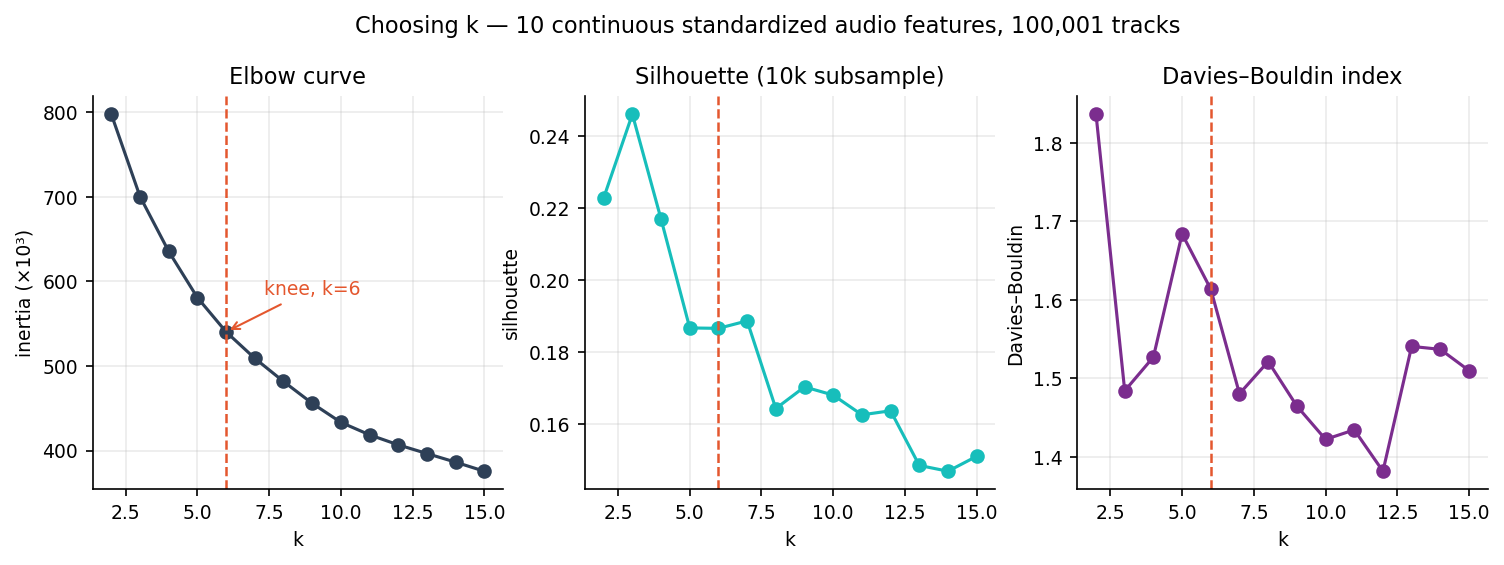

In [5]:
knee_k = knee(sw10)
fig, ax = plt.subplots(1, 3, figsize=(12, 3.4))
ax[0].plot(sw10.k, sw10.inertia/1e3, "o-", color="#2E4057")
ax[0].axvline(K_FINAL, color="#E4572E", ls="--", lw=1.2)
ax[0].annotate(f"knee, k={knee_k}",
               (knee_k, sw10.inertia[sw10.k == knee_k].iloc[0]/1e3),
               textcoords="offset points", xytext=(18, 18), color="#E4572E",
               arrowprops=dict(arrowstyle="->", color="#E4572E"))
ax[0].set(xlabel="k", ylabel="inertia (×10³)", title="Elbow curve")
ax[1].plot(sw10.k, sw10.silhouette, "o-", color="#17BEBB")
ax[1].axvline(K_FINAL, color="#E4572E", ls="--", lw=1.2)
ax[1].set(xlabel="k", ylabel="silhouette", title="Silhouette (10k subsample)")
ax[2].plot(sw10.k, sw10.davies_bouldin, "o-", color="#7B2D8E", label="Davies–Bouldin (↓)")
ax[2].axvline(K_FINAL, color="#E4572E", ls="--", lw=1.2)
ax[2].set(xlabel="k", ylabel="Davies–Bouldin", title="Davies–Bouldin index")
fig.suptitle(f"Choosing k — 10 continuous standardized audio features, {len(tracks):,} tracks", y=1.04)
save_fig(fig, "01_elbow_silhouette.png")

**Decision.** Silhouette's global maximum is k = 3 (0.246), but that solution only separates
spoken word, energetic music and quiet acoustic music — too coarse for an explorer with a
legend and per-tribe pages. The elbow sits at k = 6. k = 7 scores slightly higher on silhouette
(0.189 vs 0.187), but only because it carves out a 308-track cluster of recordings longer than
15 minutes (duration +10 SD: concertos, 40-minute Umm Kulthum performances, comedy records) —
a group of extreme lengths, not a tribe — and the smallest cluster stays below ~310 tracks for
every k ≥ 7. **k = 6** is the largest k that stays degeneracy-free, and it coincides with the
elbow. Committed.

In [6]:
kmeans = KMeans(n_clusters=K_FINAL, random_state=SEED, n_init=10).fit(X)
labels = kmeans.labels_
tracks["cluster_id"] = labels
tracks["dist_to_centroid"] = np.linalg.norm(X - kmeans.cluster_centers_[labels], axis=1)
joblib.dump(kmeans, f"{OUT_DIR}/kmeans.joblib")

print("silhouette      ", round(silhouette_score(X, labels, sample_size=10000, random_state=SEED), 4))
print("davies-bouldin  ", round(davies_bouldin_score(X, labels), 4))
print("calinski-harab. ", round(calinski_harabasz_score(X, labels), 1))
pd.Series(np.bincount(labels), name="tracks").to_frame().T

silhouette       0.1867
davies-bouldin   1.6137
calinski-harab.  16809.1


,0,1,2,3,4,5
tracks,6359,21846,4820,8430,25710,32836


## 3. Cluster profiles

Centroids are reported twice: in standard deviations (what drove the split) and back in raw
units (what a human can read). `scaler.inverse_transform` needs all 12 columns, so raw units
are recovered by undoing the standardization on the 10 model columns: `mean_ + scale_ × z`.

In [7]:
centers_std = pd.DataFrame(kmeans.cluster_centers_, columns=FEATURES)
centers_raw = pd.DataFrame(scaler.mean_[FEAT_IDX] + scaler.scale_[FEAT_IDX] * kmeans.cluster_centers_,
                           columns=FEATURES)
centers_std.to_csv(f"{OUT_DIR}/cluster_centroids_standardized.csv", index_label="cluster_id")
centers_raw.to_csv(f"{OUT_DIR}/cluster_centroids_raw_units.csv", index_label="cluster_id")

# mode is not in the model, but it is still worth describing: no tribe should be defined by key
print("major-key share per cluster:", tracks.groupby("cluster_id")["mode"].mean().round(3).to_dict())
centers_std.round(2)

major-key share per cluster: {0: 0.675, 1: 0.644, 2: 0.665, 3: 0.669, 4: 0.692, 5: 0.637}


,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_ms
0,-0.31,0.51,0.29,-0.06,-0.19,-0.14,2.75,0.02,0.06,0.31
1,-0.42,0.80,0.65,-0.19,-0.88,-0.06,-0.16,-0.32,0.70,0.15
2,0.61,-0.57,-1.06,4.05,0.52,-0.40,0.87,0.04,-0.55,-0.62
3,-0.83,-1.11,-1.37,-0.28,1.08,2.63,-0.24,-0.63,-0.35,0.15
4,-0.47,-0.94,-0.52,-0.30,0.85,-0.33,-0.26,-0.59,-0.26,-0.05
5,0.82,0.48,0.42,-0.15,-0.41,-0.29,-0.29,0.81,-0.10,-0.07


In [8]:
names = json.load(open(f"{OUT_DIR}/cluster_names.json"))   # authored by hand from these profiles, see §4
NAME   = {int(k): v["name"] for k, v in names.items()}
LABELS = [f"{c} · {NAME[c]}" for c in range(K_FINAL)]

# The hand-written names are keyed by cluster id. If K-Means ever numbers the clusters
# differently, stop here rather than publish mislabelled tribes.
for feat, name in {"liveness": "Live on Stage", "energy": "High-Voltage Anthems",
                   "speechiness": "Spoken Word & Audio Drama",
                   "instrumentalness": "Instrumental Meditations", "valence": "Sunlit Grooves"}.items():
    assert NAME[int(centers_std[feat].idxmax())] == name, f"cluster ids changed: highest {feat} is not '{name}'"
NAME

{0: 'Live on Stage',
 1: 'High-Voltage Anthems',
 2: 'Spoken Word & Audio Drama',
 3: 'Instrumental Meditations',
 4: 'Acoustic Storytellers',
 5: 'Sunlit Grooves'}

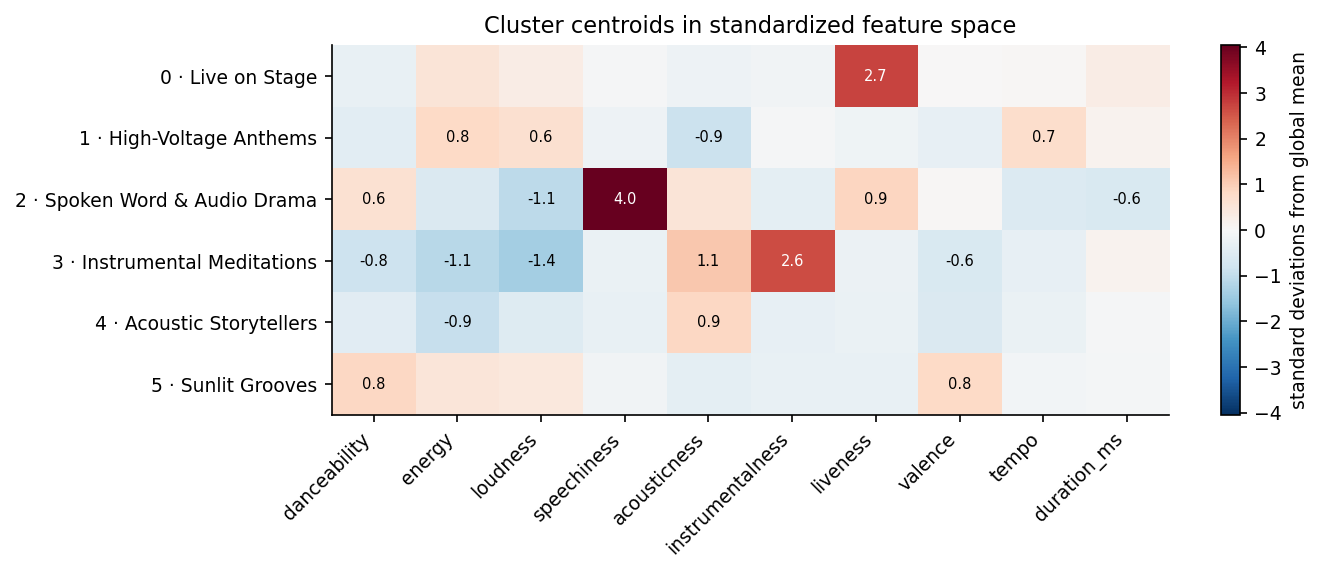

In [9]:
fig, ax = plt.subplots(figsize=(9, 3.2))
M = centers_std[FEATURES].values
v = np.abs(M).max()
im = ax.imshow(M, cmap="RdBu_r", vmin=-v, vmax=v, aspect="auto")
ax.set_xticks(range(len(FEATURES)))
ax.set_xticklabels(FEATURES, rotation=45, ha="right")
ax.set_yticks(range(K_FINAL))
ax.set_yticklabels(LABELS)
for i in range(M.shape[0]):
    for j in range(M.shape[1]):
        if abs(M[i, j]) > 0.6:
            ax.text(j, i, f"{M[i,j]:.1f}", ha="center", va="center", fontsize=7,
                    color="white" if abs(M[i, j]) > v*.6 else "black")
ax.grid(False)
fig.colorbar(im, label="standard deviations from global mean")
ax.set_title("Cluster centroids in standardized feature space")
save_fig(fig, "02_centroid_heatmap.png")

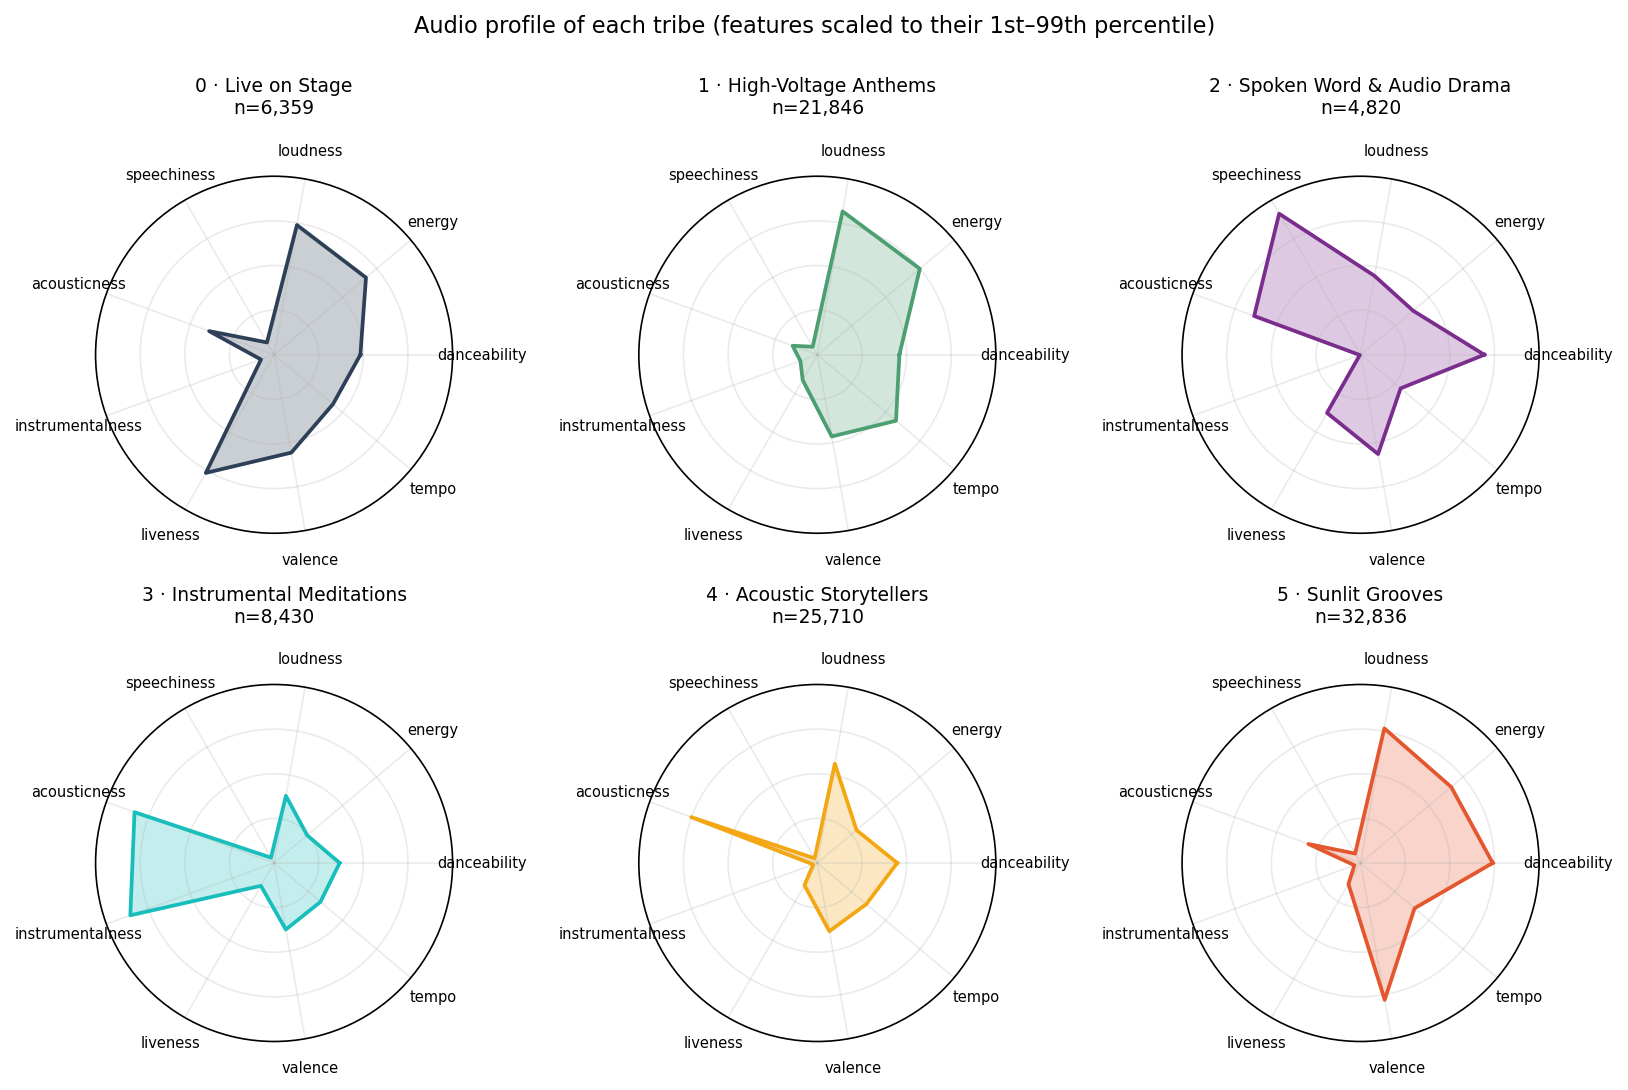

In [10]:
q = tracks[RADAR_FEATURES].quantile([0.01, 0.99])
radar = tracks.groupby("cluster_id")[RADAR_FEATURES].mean()
radar = ((radar - q.loc[0.01]) / (q.loc[0.99] - q.loc[0.01])).clip(0, 1)
ang = np.linspace(0, 2*np.pi, len(RADAR_FEATURES), endpoint=False).tolist()
ang += ang[:1]
fig, axes = plt.subplots(2, 3, figsize=(11, 7.2), subplot_kw=dict(polar=True))
for c, a in zip(range(K_FINAL), axes.ravel()):
    vals = radar.loc[c].tolist(); vals += vals[:1]
    a.plot(ang, vals, color=PALETTE[c], lw=1.8)
    a.fill(ang, vals, color=PALETTE[c], alpha=.25)
    a.set_xticks(ang[:-1]); a.set_xticklabels(RADAR_FEATURES, size=7)
    a.set_yticks([.25, .5, .75]); a.set_yticklabels([], size=6); a.set_ylim(0, 1)
    a.set_title(f"{LABELS[c]}\nn={int((labels == c).sum()):,}", size=9, pad=14)
for a in axes.ravel()[K_FINAL:]:
    a.axis("off")
fig.suptitle("Audio profile of each tribe (features scaled to their 1st–99th percentile)", y=1.0)
fig.tight_layout()
save_fig(fig, "03_cluster_radar.png")

### Validation against human genre labels

The plan's test: does an unsupervised cluster line up with the genre labels in `artists.csv`?
Raw Spotify genres are far too fine-grained (thousands of strings like *mellow gold*,
*stride*), so each track's artist genres are mapped to one of nine coarse buckets by keyword.

In [11]:
BUCKETS = {
    'Hip-Hop / Rap':      ['hip hop','rap','trap','drill','grime'],
    'Electronic / Dance': ['edm','house','techno','trance','dubstep','electro','drum and bass','dance pop','dance rock'],
    'Rock / Metal':       ['rock','metal','punk','grunge'],
    'Classical':          ['classical','opera','baroque','orchestra','romantic era','choral','chamber'],
    'Jazz / Standards':   ['jazz','bebop','swing','adult standards','vocal jazz','lounge','bossa'],
    'Country / Folk':     ['country','folk','bluegrass','americana'],
    'Latin / World':      ['latin','salsa','tango','reggaeton','tropical','bolero','ranchera','mpb','samba','filmi'],
    'Pop':                ['pop'],
    'Spoken Word':        ['hoerspiel','reading','barnsagor','comedy','poetry','audiobook','spoken','kindermusik','barnmusik'],
}
def bucket(gs):
    for g in gs:                       # artist_genres is an ndarray, not a list
        for b, keys in BUCKETS.items():
            if any(kk in g for kk in keys):
                return b
    return None

tracks["genre_bucket"] = tracks["artist_genres"].apply(bucket)
m = tracks.genre_bucket.notna().values
print("labelled coverage", round(m.mean(), 3))
print("NMI(cluster, genre bucket)", round(normalized_mutual_info_score(tracks.genre_bucket[m], labels[m]), 4))
genre_ct = pd.crosstab(tracks.cluster_id, tracks.genre_bucket, normalize="index")
(genre_ct * 100).round(1)

labelled coverage 0.772
NMI(cluster, genre bucket) 0.1572


genre_bucket,Classical,Country / Folk,Electronic / Dance,Hip-Hop / Rap,Jazz / Standards,Latin / World,Pop,Rock / Metal,Spoken Word
cluster_id,,,,,,,,,
0,1.9,4.9,5.5,6.0,10.7,11.0,30.8,27.2,2.0
1,0.3,3.1,9.5,7.2,3.3,4.6,33.8,38.0,0.3
2,1.0,2.3,0.3,1.6,1.4,0.3,5.4,2.7,85.0
3,37.3,3.4,2.4,0.4,28.1,7.3,11.0,10.1,0.0
4,6.9,10.4,1.3,1.8,20.6,8.6,38.3,11.5,0.6
5,0.3,5.2,5.6,13.9,8.8,10.4,38.6,16.7,0.6


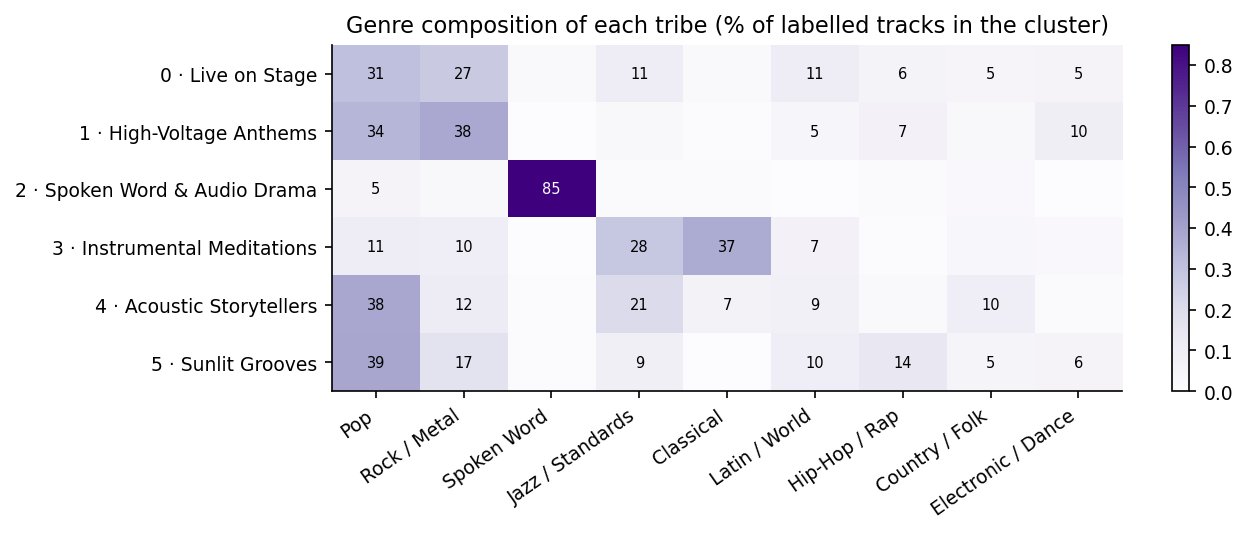

In [12]:
ct = genre_ct[genre_ct.sum().sort_values(ascending=False).index]
fig, ax = plt.subplots(figsize=(8.5, 3.0))
im = ax.imshow(ct.values, cmap="Purples", vmin=0, vmax=ct.values.max(), aspect="auto")
ax.set_xticks(range(len(ct.columns))); ax.set_xticklabels(ct.columns, rotation=35, ha="right")
ax.set_yticks(range(K_FINAL)); ax.set_yticklabels(LABELS)
for i in range(ct.shape[0]):
    for j in range(ct.shape[1]):
        if ct.values[i, j] > .04:
            ax.text(j, i, f"{100*ct.values[i,j]:.0f}", ha="center", va="center", fontsize=7,
                    color="white" if ct.values[i, j] > ct.values.max()*.6 else "black")
ax.grid(False)
ax.set_title("Genre composition of each tribe (% of labelled tracks in the cluster)")
fig.colorbar(im)
save_fig(fig, "06_genre_validation.png")

### Per-cluster tables: genres, decades, artists, representative songs

In [13]:
exploded = tracks[["cluster_id","artist_genres"]].explode("artist_genres").dropna()
profiles = {}
for c in range(K_FINAL):
    sub    = tracks[tracks.cluster_id == c]
    inner  = sub[sub.dist_to_centroid <= sub.dist_to_centroid.quantile(0.25)]
    profiles[c] = dict(
        size=int(len(sub)), share=round(len(sub)/len(tracks), 4),
        mean_popularity=round(float(sub.popularity.mean()), 2),
        mean_pop_z=round(float(sub.pop_z.mean()), 3),
        median_year=int(sub.release_year.median()),
        major_key_share=round(float(sub["mode"].mean()), 3),
        centroid_standardized={f: round(float(v),3) for f,v in centers_std.loc[c].items()},
        centroid_raw_units={f: round(float(v),3) for f,v in centers_raw.loc[c].items()},
        top_genres=[[g,int(n)] for g,n in exploded[exploded.cluster_id==c]["artist_genres"]
                                            .value_counts().head(10).items()],
        top_genre_buckets=[[b,round(float(p),3)] for b,p in
                           sub.genre_bucket.value_counts(normalize=True).head(5).items()],
        top_decades=[[int(d),int(n)] for d,n in sub.decade.value_counts().head(5).items()],
        top_artists=[[a,int(n)] for a,n in sub.primary_artist_name.value_counts().head(20).items()],
        closest_songs=[{"name":r["name"],"artist":r.primary_artist_name,"year":int(r.release_year),
                        "popularity":int(r.popularity),"dist":round(float(r.dist_to_centroid),3)}
                       for _,r in sub.nsmallest(20,"dist_to_centroid").iterrows()],
        showcase_songs=[{"name":r["name"],"artist":r.primary_artist_name,"year":int(r.release_year),
                         "popularity":int(r.popularity)}
                        for _,r in inner.nlargest(20,"popularity").iterrows()],
    )
    print(f"{c}: n={len(sub):6d}  {[g for g,_ in profiles[c]['top_genres'][:4]]}")

0: n=  6359  ['rock', 'classic rock', 'album rock', 'mellow gold']
1: n= 21846  ['rock', 'classic rock', 'album rock', 'hard rock']
2: n=  4820  ['hoerspiel', 'kleine hoerspiel', 'barnsagor', 'reading']
3: n=  8430  ['classical', 'cool jazz', 'jazz', 'adult standards']
4: n= 25710  ['adult standards', 'vocal jazz', 'lounge', 'filmi']
5: n= 32836  ['latin', 'rock', 'classic rock', 'tropical']


## 4. Naming the tribes

Names come from the centroid profile plus the genre and artist tables above — not from the
genre labels, which are only used to check the result afterwards.

| id | name | what defines it |
|----|------|-----------------|
| 0 | Live on Stage | liveness +2.75 SD — a recording context, not a genre |
| 1 | High-Voltage Anthems | energy +0.80, loudness +0.65, tempo +0.70 SD, acousticness −0.88 SD; rock, metal, electronic |
| 2 | Spoken Word & Audio Drama | speechiness +4.05 SD; 85% spoken-word labels; not music |
| 3 | Instrumental Meditations | instrumentalness +2.63 SD; quiet, acoustic; classical and jazz |
| 4 | Acoustic Storytellers | acoustic, low energy, low valence, vocals present |
| 5 | Sunlit Grooves | danceability +0.82, valence +0.81 SD; bright, danceable, feel-good |

Every tribe is 64–69% major key, close to the corpus-wide 66%: with `mode` out of the distance,
key signature no longer defines any tribe. `cluster_names.json` carries the names, taglines,
descriptions and justifications (loaded in §3 so the profile figures are labelled).

## 5. How each tribe moved across a century

In [14]:
by_dec_counts = pd.crosstab(tracks.decade, tracks.cluster_id)
by_dec_share  = pd.crosstab(tracks.decade, tracks.cluster_id, normalize="index")
by_dec_counts.to_csv(f"{OUT_DIR}/cluster_by_decade_counts.csv")
by_dec_share.round(4).to_csv(f"{OUT_DIR}/cluster_by_decade_share.csv")
(by_dec_share*100).round(1).rename(columns=NAME)

cluster_id,Live on Stage,High-Voltage Anthems,Spoken Word & Audio Drama,Instrumental Meditations,Acoustic Storytellers,Sunlit Grooves
decade,,,,,,
1920,1.6,1.2,28.6,28.5,28.7,11.5
1930,3.8,2.5,15.8,27.0,40.4,10.3
1940,4.0,1.6,3.6,39.4,42.8,8.7
1950,4.1,2.2,6.5,24.4,50.0,12.9
1960,6.0,7.8,3.0,14.9,44.6,23.6
1970,7.7,16.7,6.0,7.3,33.1,29.2
1980,6.2,20.0,10.9,5.2,24.1,33.7
1990,6.8,23.7,4.8,4.9,22.4,37.4
2000,7.7,31.3,1.4,2.8,16.4,40.5


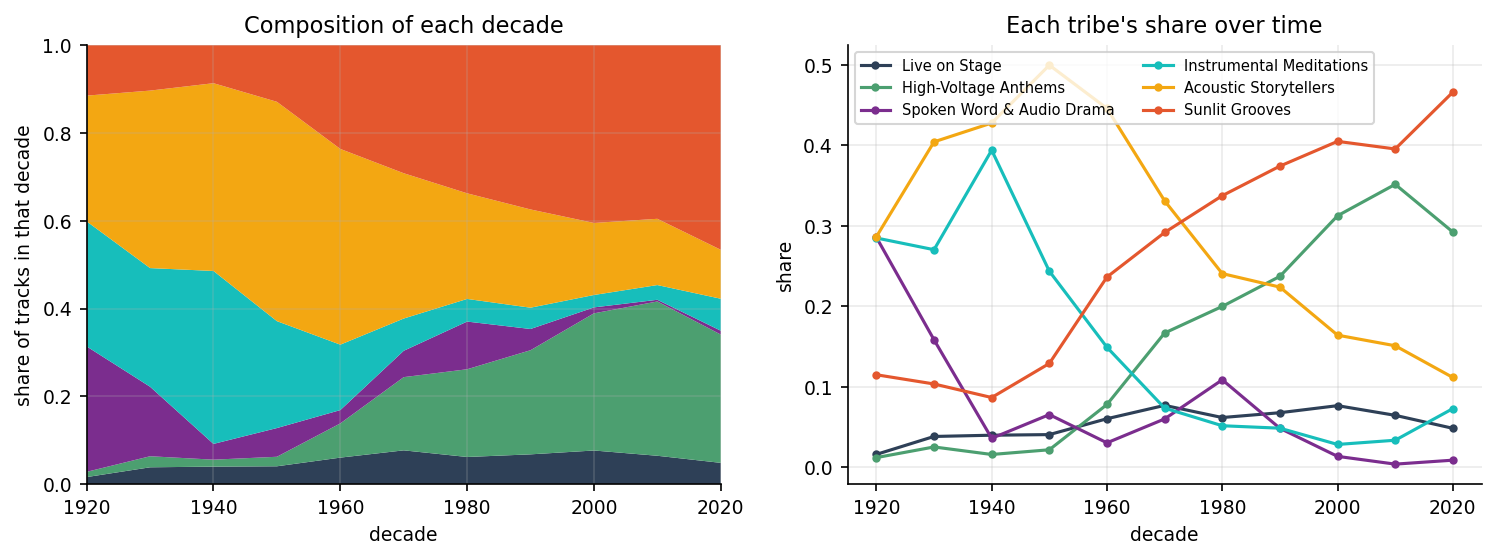

In [15]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].stackplot(by_dec_share.index, [by_dec_share[c] for c in range(K_FINAL)],
                colors=PALETTE, labels=[NAME[c] for c in range(K_FINAL)])
ax[0].set(xlabel="decade", ylabel="share of tracks in that decade", ylim=(0, 1),
          title="Composition of each decade")
ax[0].margins(x=0)
for c in range(K_FINAL):
    ax[1].plot(by_dec_share.index, by_dec_share[c], "o-", color=PALETTE[c], ms=3, label=NAME[c])
ax[1].set(xlabel="decade", ylabel="share", title="Each tribe's share over time")
ax[1].legend(fontsize=7, ncol=2)
save_fig(fig, "04_evolution_by_decade.png")

## 6. PCA — the linear baseline

In [16]:
pca = PCA(n_components=2, random_state=SEED)
P = pca.fit_transform(X)
tracks["pca_x"], tracks["pca_y"] = P[:,0], P[:,1]
joblib.dump(pca, f"{OUT_DIR}/pca.joblib")

['outputs/music_tribes/pca.joblib']

In [17]:
print("explained variance:", pca.explained_variance_ratio_.round(4),
      "| cumulative:", round(pca.explained_variance_ratio_.sum(), 4))
pd.DataFrame(pca.components_.T, index=FEATURES, columns=["PC1","PC2"]).round(3)

explained variance: [0.2885 0.1546] | cumulative: 0.443


,PC1,PC2
danceability,0.298,0.481
energy,0.520,-0.168
loudness,0.484,-0.185
speechiness,-0.032,0.538
acousticness,-0.446,0.199
instrumentalness,-0.247,-0.209
liveness,0.032,0.092
valence,0.334,0.360
tempo,0.182,-0.238
duration_ms,-0.022,-0.372


PC1 (28.9%) is the acoustic-to-electric axis: energy, loudness, valence and danceability
against acousticness. PC2 (15.5%) is talk and groove — speechiness, danceability and valence
against duration. Two components hold only **44.3%** of the variance, which is why the PCA
scatter is one dense cloud rather than a map.

## 7. UMAP — the projection used for the website

In [18]:
import umap
t0 = time.time()
U = umap.UMAP(n_components=2, n_neighbors=15, min_dist=0.1,
              metric="euclidean", random_state=SEED).fit_transform(X)
tracks["umap_x"], tracks["umap_y"] = U[:,0], U[:,1]
print("umap on 10 features:", round(time.time()-t0, 1), "s")

rng = np.random.default_rng(SEED); idx = rng.choice(len(X), 5000, replace=False)
print("trustworthiness  PCA:", round(trustworthiness(X[idx], P[idx], n_neighbors=15), 4),
      "| UMAP:",              round(trustworthiness(X[idx], U[idx], n_neighbors=15), 4))
print("corr(UMAP-1, mode):",  round(np.corrcoef(tracks.umap_x, tracks['mode'])[0,1], 3))

umap on 10 features: 59.7 s


trustworthiness  PCA: 0.813 | UMAP: 0.9282
corr(UMAP-1, mode): -0.017


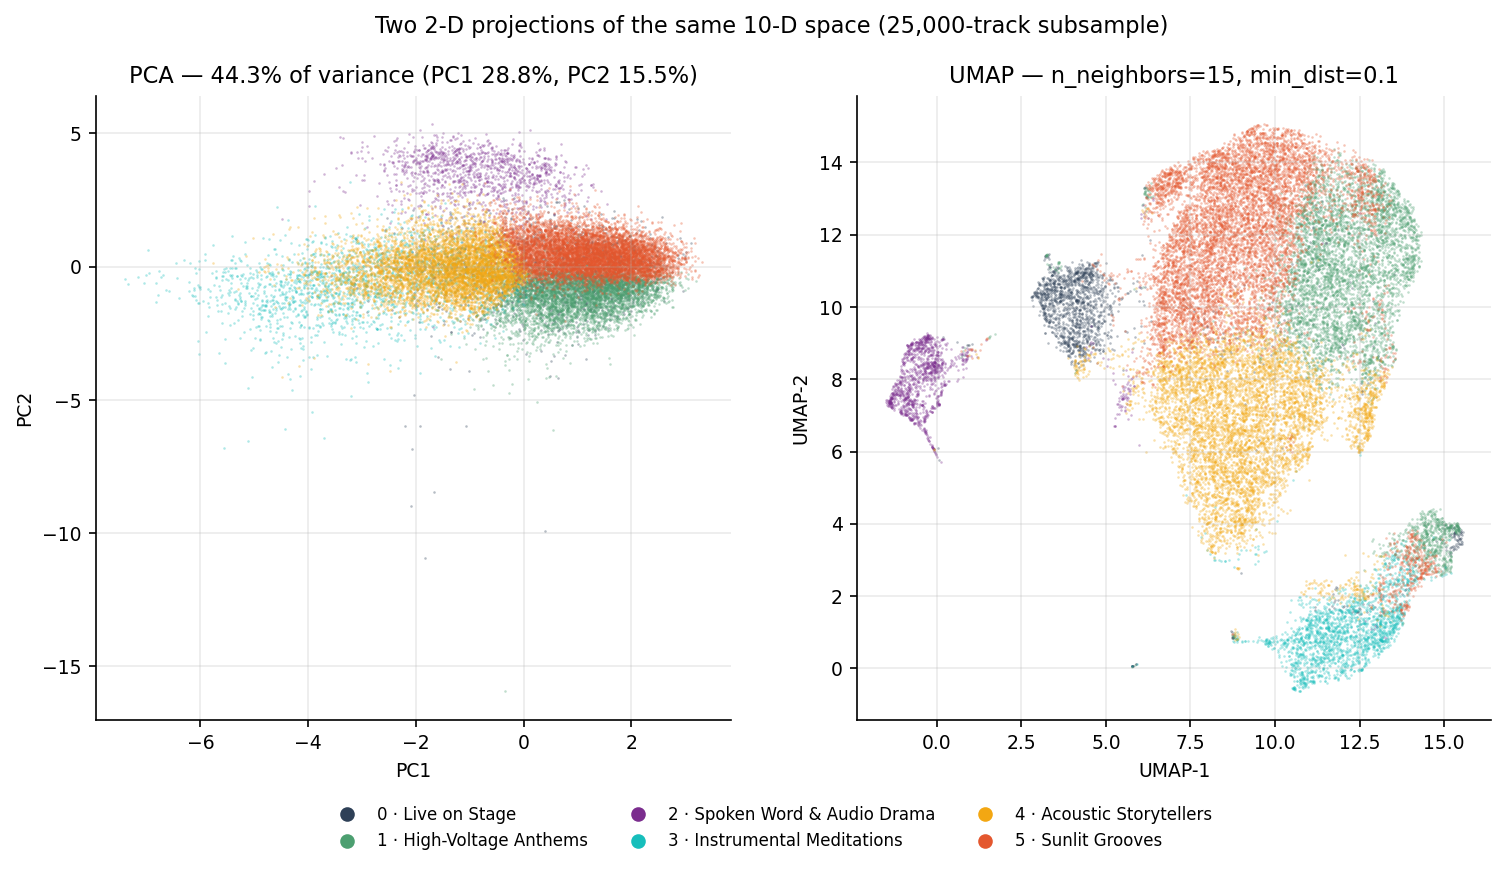

In [19]:
def tribe_legend(fig):
    fig.legend(handles=[Line2D([], [], marker="o", ls="", color=PALETTE[c], label=LABELS[c])
                        for c in range(K_FINAL)],
               loc="lower center", ncol=3, fontsize=8, frameon=False, bbox_to_anchor=(.5, -.07))

sub = tracks.iloc[np.random.default_rng(SEED).choice(len(tracks), 25000, replace=False)]
fig, ax = plt.subplots(1, 2, figsize=(12, 5.4))
for c in range(K_FINAL):
    sel = sub.cluster_id == c
    ax[0].scatter(sub.pca_x[sel],  sub.pca_y[sel],  s=1.5, c=PALETTE[c], alpha=.35, lw=0)
    ax[1].scatter(sub.umap_x[sel], sub.umap_y[sel], s=1.5, c=PALETTE[c], alpha=.35, lw=0)
evr = pca.explained_variance_ratio_
ax[0].set(title=f"PCA — {100*sum(evr):.1f}% of variance "
                f"(PC1 {100*evr[0]:.1f}%, PC2 {100*evr[1]:.1f}%)",
          xlabel="PC1", ylabel="PC2")
ax[1].set(title="UMAP — n_neighbors=15, min_dist=0.1", xlabel="UMAP-1", ylabel="UMAP-2")
tribe_legend(fig)
fig.suptitle("Two 2-D projections of the same 10-D space (25,000-track subsample)")
save_fig(fig, "05_pca_vs_umap.png")

UMAP preserves local neighbourhoods far better than PCA (trustworthiness 0.928 vs 0.813 at
k = 15). Its axes do not follow key signature (correlation with `mode` −0.017), so neighbours
on the map are songs that sound alike whatever their key. The map is one main continent —
Sunlit Grooves and High-Voltage Anthems side by side at the top, Acoustic Storytellers below —
with Live on Stage, Spoken Word and Instrumental Meditations as separate islands. The cost is
that distances between islands carry no quantitative meaning; only neighbourhoods do.

## 8. Sensitivity — what adding the two non-continuous features would cost

`mode` is binary and `time_signature` is near-constant. After standardization each would carry
variance 1, the same as energy, and Euclidean geometry cannot tell that one of them is a
category rather than a quantity. This section re-runs the clustering and the map on all 12
features — **still using the shared scaler**, just keeping all 12 of its output columns — to
show what including them would do.

In [20]:
km12 = KMeans(K_FINAL, random_state=SEED, n_init=10).fit(X12)
tracks["cluster12_id"] = km12.labels_
joblib.dump(km12, f"{OUT_DIR}/kmeans_12feature_sensitivity.joblib")

C12 = km12.cluster_centers_[:, FEAT_IDX]          # 12-feature centroids, read in the 10 continuous dims
pairs = sorted([(i, j, round(float(np.linalg.norm(C12[i]-C12[j])), 3))
                for i in range(K_FINAL) for j in range(i+1, K_FINAL)], key=lambda t: t[2])
print("12-feature run, closest centroid pairs in the 10 continuous dimensions:", pairs[:3])
print("12-feature run, major-key share per cluster:",
      tracks.groupby('cluster12_id')['mode'].mean().round(3).to_dict())

12-feature run, closest centroid pairs in the 10 continuous dimensions: [(0, 5, 0.232), (3, 5, 2.688), (0, 3, 2.777)]
12-feature run, major-key share per cluster: {0: 1.0, 1: 0.676, 2: 0.712, 3: 0.748, 4: 0.667, 5: 0.0}


In [21]:
U12 = umap.UMAP(n_components=2, n_neighbors=15, min_dist=0.1,
                metric="euclidean", random_state=SEED).fit_transform(X12)
tracks["umap12_x"], tracks["umap12_y"] = U12[:,0], U12[:,1]

print("silhouette     10 vs 12:", round(silhouette_score(X, labels, sample_size=10000, random_state=SEED),4),
      "vs", round(silhouette_score(X12, km12.labels_, sample_size=10000, random_state=SEED),4))
print("Davies-Bouldin 10 vs 12:", round(davies_bouldin_score(X, labels),4),
      "vs", round(davies_bouldin_score(X12, km12.labels_),4))
print("NMI vs genre   10 vs 12:", round(normalized_mutual_info_score(tracks.genre_bucket[m], labels[m]),4),
      "vs", round(normalized_mutual_info_score(tracks.genre_bucket[m], km12.labels_[m]),4))
print("ARI between the two runs:", round(adjusted_rand_score(labels, km12.labels_),4))
print("corr(UMAP-1, mode) 10 vs 12:", round(np.corrcoef(tracks.umap_x, tracks['mode'])[0,1],3),
      "vs", round(np.corrcoef(tracks.umap12_x, tracks['mode'])[0,1],3))

silhouette     10 vs 12: 0.1867 vs 0.161
Davies-Bouldin 10 vs 12: 1.6137 vs 1.7884
NMI vs genre   10 vs 12: 0.1572 vs 0.1443
ARI between the two runs: 0.493


corr(UMAP-1, mode) 10 vs 12: -0.017 vs -0.906


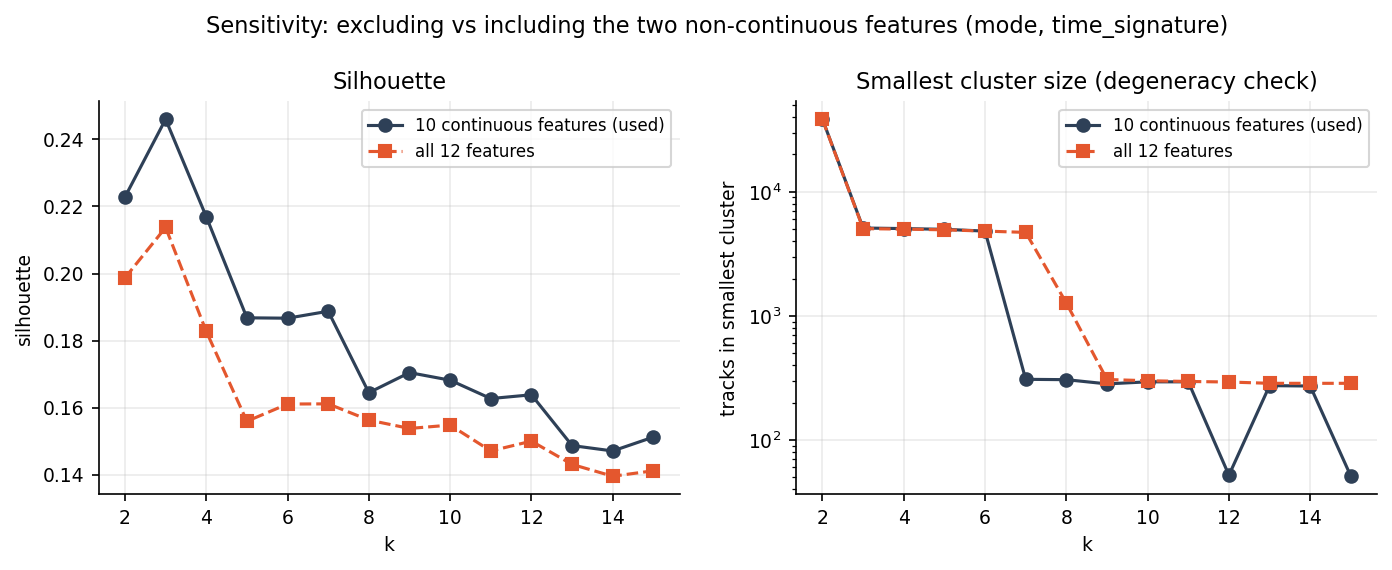

In [22]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
ax[0].plot(sw10.k, sw10.silhouette, "o-", color="#2E4057", label="10 continuous features (used)")
ax[0].plot(sw12.k, sw12.silhouette, "s--", color="#E4572E", label="all 12 features")
ax[0].set(xlabel="k", ylabel="silhouette", title="Silhouette")
ax[0].legend(fontsize=8)
ax[1].plot(sw10.k, sw10.smallest_cluster, "o-", color="#2E4057", label="10 continuous features (used)")
ax[1].plot(sw12.k, sw12.smallest_cluster, "s--", color="#E4572E", label="all 12 features")
ax[1].set(xlabel="k", ylabel="tracks in smallest cluster", yscale="log",
          title="Smallest cluster size (degeneracy check)")
ax[1].legend(fontsize=8)
fig.suptitle("Sensitivity: excluding vs including the two non-continuous features "
             "(mode, time_signature)", y=1.05)
save_fig(fig, "07_sensitivity_12_vs_10.png")

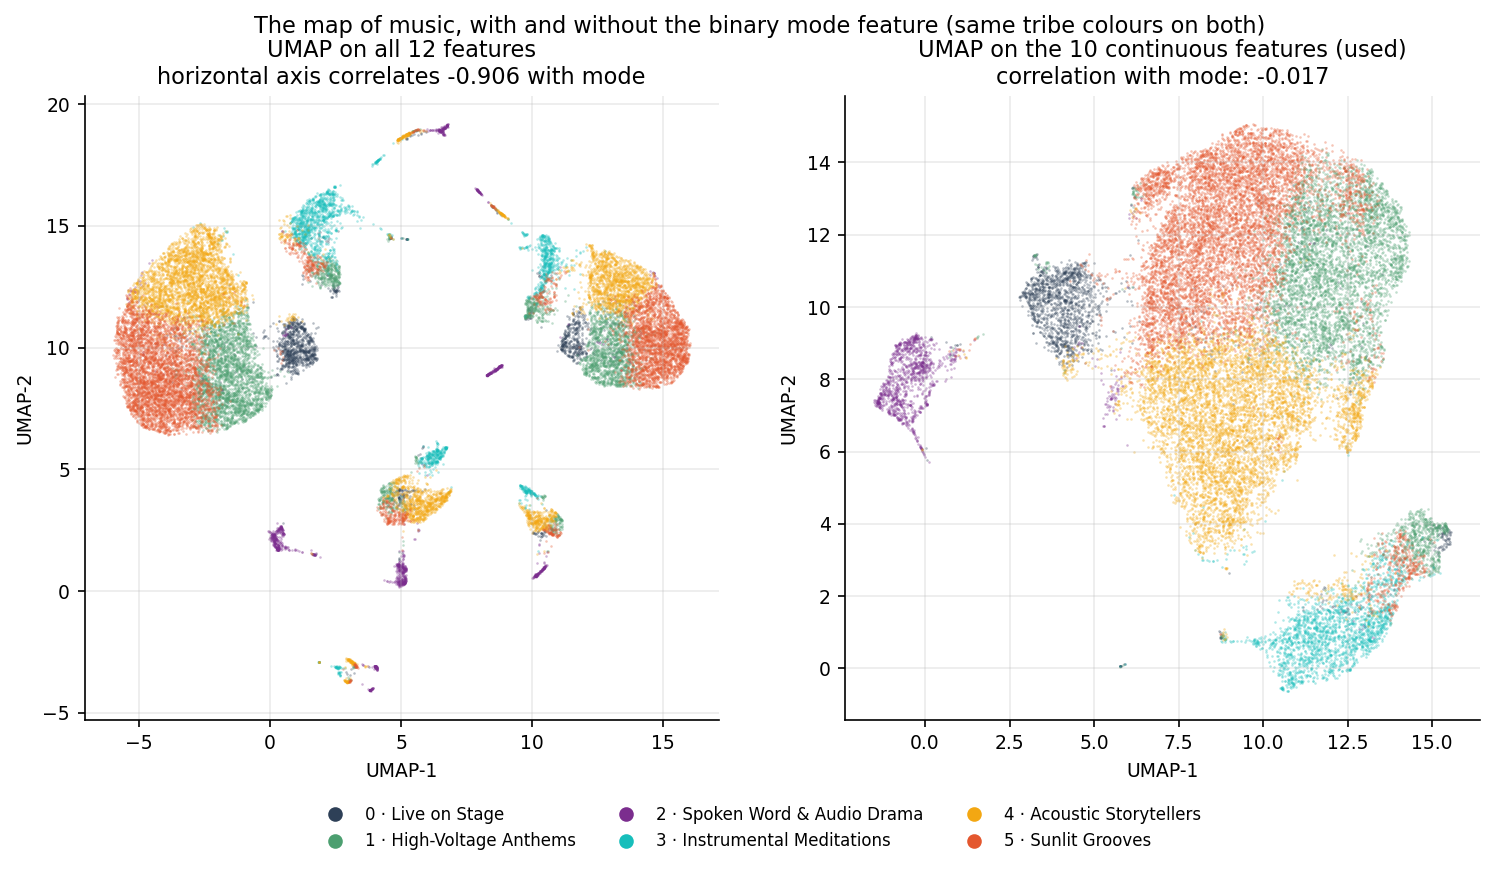

In [23]:
r10 = np.corrcoef(tracks.umap_x,   tracks["mode"])[0, 1]
r12 = np.corrcoef(tracks.umap12_x, tracks["mode"])[0, 1]
sub = tracks.iloc[np.random.default_rng(SEED).choice(len(tracks), 25000, replace=False)]

fig, ax = plt.subplots(1, 2, figsize=(12, 5.4))
for c in range(K_FINAL):
    sel = sub.cluster_id == c
    ax[0].scatter(sub.umap12_x[sel], sub.umap12_y[sel], s=1.5, c=PALETTE[c], alpha=.35, lw=0)
    ax[1].scatter(sub.umap_x[sel],   sub.umap_y[sel],   s=1.5, c=PALETTE[c], alpha=.35, lw=0)
ax[0].set(title=f"UMAP on all 12 features\nhorizontal axis correlates {r12:.3f} with mode",
          xlabel="UMAP-1", ylabel="UMAP-2")
ax[1].set(title=f"UMAP on the 10 continuous features (used)\ncorrelation with mode: {r10:.3f}",
          xlabel="UMAP-1", ylabel="UMAP-2")
tribe_legend(fig)
fig.suptitle("The map of music, with and without the binary mode feature (same tribe colours on both)")
save_fig(fig, "08_umap_12_vs_10.png")

Including `mode` and `time_signature` makes every internal measure worse — silhouette 0.161 vs
0.187, Davies–Bouldin 1.788 vs 1.614, genre NMI 0.144 vs 0.157 — and the damage is visible in
the solution itself. Two of the six 12-feature clusters sit only 0.232 apart in the 10
continuous dimensions (the next-closest pair is 2.688 apart), and one is 100% major key while
the other is 100% minor: a single sonic tribe split in two by key signature. The 12-feature
map shows the same thing at full scale: its first axis correlates −0.906 with `mode`, dividing
the corpus into a major-key and a minor-key continent that each hold a copy of every tribe
(left panel above). The two solutions agree only moderately (ARI = 0.493).

This is why the model uses the 10 continuous features. The 12-feature run is kept as
`kmeans_12feature_sensitivity.joblib` and as the alternative `x12`/`y12` projection in
`map_data.json`.

## 9. Exports for the website and the report

In [24]:
tracks.to_parquet(f"{OUT_DIR}/tracks_clustered.parquet", index=False)

# ~5,000 songs for the in-browser map: proportional across clusters, stratified by decade inside each
TARGET, rng = 5000, np.random.default_rng(SEED)
sizes = tracks.cluster_id.value_counts().sort_index()
alloc = np.maximum((sizes/sizes.sum()*TARGET).round().astype(int), 150)
parts = []
for c in range(K_FINAL):
    sub  = tracks[tracks.cluster_id == c]
    n    = min(int(alloc[c]), len(sub)); frac = n/len(sub)
    take = pd.concat([g.sample(min(len(g), max(1, round(len(g)*frac))), random_state=SEED)
                      for _, g in sub.groupby("decade")])
    parts.append(take.sample(n, random_state=SEED) if len(take) > n else take)
sample = pd.concat(parts).sample(frac=1, random_state=SEED).reset_index(drop=True)

map_payload = {"meta": {"n_songs": int(len(sample)), "k": K_FINAL, "seed": SEED,
                        "features": FEATURES,
                        "primary_projection": "x,y = UMAP on the 10 continuous features (the model's space)",
                        "alternative_projection": "x12,y12 = UMAP on all 12 features (sensitivity check; splits by mode)"},
               "songs": [{"id": r.id, "song": r["name"], "artist": r.primary_artist_name,
                          "year": int(r.release_year), "decade": int(r.decade),
                          "popularity": int(r.popularity), "cluster_id": int(r.cluster_id),
                          "cluster_name": NAME[int(r.cluster_id)],
                          "x": round(float(r.umap_x),3),  "y": round(float(r.umap_y),3),
                          "x12": round(float(r.umap12_x),3), "y12": round(float(r.umap12_y),3),
                          "pca_x": round(float(r.pca_x),3), "pca_y": round(float(r.pca_y),3),
                          "cluster12_id": int(r.cluster12_id)} for _, r in sample.iterrows()]}
json.dump(map_payload, open(f"{OUT_DIR}/map_data.json","w"), separators=(",",":"))
print("map_data.json:", len(map_payload["songs"]), "songs")

map_data.json: 4998 songs


In [25]:
sil_sub = rng.choice(len(X), 20000, replace=False)
sv = silhouette_samples(X[sil_sub], labels[sil_sub])

meta = {"meta": {"k": K_FINAL, "seed": SEED, "n_tracks": int(len(tracks)),
                 "features": FEATURES, "features_excluded": ["mode", "time_signature"],
                 "silhouette": round(float(silhouette_score(X, labels, sample_size=10000, random_state=SEED)), 4)},
        "clusters": []}
for c in range(K_FINAL):
    p = profiles[c]
    meta["clusters"].append({**p, "cluster_id": c, "name": NAME[c],
        "tagline": names[str(c)]["tagline"], "description": names[str(c)]["description"],
        "naming_justification": names[str(c)]["naming_justification"], "colour": PALETTE[c],
        "silhouette": round(float(sv[labels[sil_sub]==c].mean()), 3),
        "radar": {f: round(float(tracks[tracks.cluster_id==c][f].mean()), 3)
                  for f in RADAR_FEATURES},
        "share_by_decade": {str(d): float(by_dec_share.loc[d, c]) for d in by_dec_share.index},
        "count_by_decade": {str(d): int(by_dec_counts.loc[d, c]) for d in by_dec_counts.index}})
json.dump(meta, open(f"{OUT_DIR}/cluster_metadata.json","w"), indent=2)
print("cluster_metadata.json written")

cluster_metadata.json written
